# Merged HMM signals, 2004–2025

- Original six-model run plus the two GMM models with three components per state.
- GMM (M=2) and GMM (M=3) remain separate strategies; no signals are averaged or overwritten.
- Source runs have identical decision dates, training-window lengths, and refresh flags. This does not establish that every historical code setting was identical.
- The merged results are for analysis, not for resuming training. Original checkpoints remain in their source folders.
- Plots and tables are generated inline. Strategy evaluation uses the existing 12-day median rule and next-day price returns; costs are excluded.


In [10]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook inside the project")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks" / "sp500"))
from paper_regime_experiment import evaluate_signals
from model_evaluation.market_strategy.evaluation import compare_strategies
from model_evaluation.market_strategy.strategies import moving_average_timing

# Read the analysis-only union; source checkpoints remain separate.
RESULT_DIR = ROOT / "notebooks/sp500/results/merged_regime_2004_2025"
signals_path = RESULT_DIR / "signals.csv"
if not signals_path.exists():
    raise FileNotFoundError(f"First run run_paper_regime.py; missing {signals_path}")
fits = pd.read_csv(signals_path, parse_dates=["date"])
prices = pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                     parse_dates=["YYYYMMDD"]).set_index("YYYYMMDD")["DlyPrcInd"]
print("Saved dates:", fits.date.min().date(), "to", fits.date.max().date())
print("Decisions:", fits.date.nunique(), "branches:", fits.groupby(["model", "pca"]).ngroups)
print("Refresh dates:", fits.loc[fits.refresh, "date"].nunique())
display(fits.groupby(["model", "pca"])[["iterations", "training_days",
                                       "n_components"]].agg(["mean", "max"]).round(1))

Saved dates: 2004-01-02 to 2025-12-30
Decisions: 5534 branches: 8
Refresh dates: 88


iterations      training_days       n_components    
                      mean  max          mean   max         mean max
model     pca                                                       
GMM (M=2) False        2.8  100        5286.5  8053         28.0  28
          True         2.1  100        5286.5  8053         10.6  11
GMM (M=3) False        3.1  100        5286.5  8053         28.0  28
          True         2.3  100        5286.5  8053         10.6  11
Gaussian  False        1.9   70        5286.5  8053         28.0  28
          True         1.4   59        5286.5  8053         10.6  11
Student-t False        3.0  100        5286.5  8053         28.0  28
          True         2.5  100        5286.5  8053         10.6  11

,total_return,sharpe,max_drawdown,exposure,turnover_per_year,total_switches,avg_persistent_days
Student-t / PCA,2.517,0.640,-0.214,0.456,5.009,110,49.856
GMM (M=3) / PCA,3.796,0.544,-0.339,0.557,4.463,98,55.899
MA 50/200,3.329,0.494,-0.339,0.776,1.002,22,240.609
Buy and hold,5.176,0.439,-0.568,1.000,0.000,0,5534.000
GMM (M=2) / no PCA,1.437,0.381,-0.339,0.430,3.871,85,64.349
GMM (M=2) / PCA,1.386,0.356,-0.292,0.367,4.872,107,51.241
Student-t / no PCA,0.684,0.329,-0.160,0.288,3.552,78,70.051
GMM (M=3) / no PCA,1.351,0.318,-0.285,0.438,4.417,97,56.469
Gaussian / no PCA,0.624,0.260,-0.226,0.204,2.049,45,120.304
Gaussian / PCA,0.606,0.243,-0.239,0.196,3.324,73,74.784


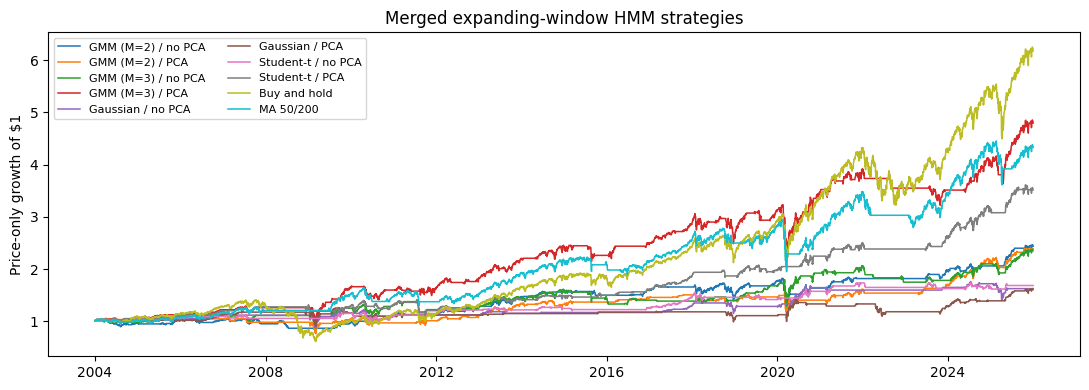

In [15]:
pnl, weights = evaluate_signals(fits, prices, median_window=12)
# moving_average_timing shifts internally: today's close sets tomorrow's position.
decision_dates = pd.DatetimeIndex(fits.date.drop_duplicates().sort_values())
next_dates = prices.index[prices.index.get_indexer(decision_dates) + 1]
ma_weights = moving_average_timing(prices, fast=50, slow=200).reindex(next_dates)
ma_weights.index = decision_dates
ma_returns = prices.pct_change(fill_method=None).reindex(next_dates)
pnl["MA 50/200"] = pd.Series(np.log1p(ma_weights.to_numpy() * ma_returns.to_numpy()),
                              index=ma_weights.index)
weights["MA 50/200"] = ma_weights
if fits.date.nunique() < 252:
    print("About one year or less: annualized estimates are noisy; interpret cautiously")
summary = compare_strategies(pnl, weights)
# Count switches and average run length in the evaluated strategy positions.
for name in summary.index:
    positions = weights[name].sort_index()
    if positions.empty or positions.isna().any():
        raise ValueError(f"Empty or missing positions for {name}")

    total_switches = int(
        np.count_nonzero(np.diff(positions.to_numpy()))
    )
    summary.loc[name, "total_switches"] = total_switches
    summary.loc[name, "avg_persistent_days"] = (
        len(positions) / (total_switches + 1)
    )

summary["total_switches"] = summary["total_switches"].astype(int)

display(summary[[
    "total_return",
    "sharpe",
    "max_drawdown",
    "exposure",
    "turnover_per_year",
    "total_switches",
    "avg_persistent_days",
]].round(3))
fig, ax = plt.subplots(figsize=(11, 4))
for name, series in pnl.items():
    ax.plot(series.index, np.exp(series.cumsum()), label=name, linewidth=1.1)
ax.set(ylabel="Price-only growth of $1", title="Merged expanding-window HMM strategies")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

In [12]:
rows = []
years = fits.date.nunique() / 252
for (name, pca), group in fits.groupby(["model", "pca"]):
    group = group.sort_values("date")
    key = f"{name} / {'PCA' if pca else 'no PCA'}"
    exposure = weights[key].to_numpy()
    raw = group.bull_raw.to_numpy()
    rows.append({"model": key, "raw switches/year": np.count_nonzero(np.diff(raw)) / years,
                 "median switches/year": np.count_nonzero(np.diff(exposure)) / years,
                 "average days/position": len(raw) / (1 + np.count_nonzero(np.diff(exposure)))})
ma_exposure = weights["MA 50/200"].to_numpy()
ma_switches = np.count_nonzero(np.diff(ma_exposure))
rows.append({"model": "MA 50/200", "raw switches/year": ma_switches / years,
             "median switches/year": ma_switches / years,
             "average days/position": len(ma_exposure) / (1 + ma_switches)})
display(pd.DataFrame(rows).set_index("model").round(2))

,raw switches/year,median switches/year,average days/position
model,,,
GMM (M=2) / no PCA,10.97,3.87,64.35
GMM (M=2) / PCA,9.70,4.87,51.24
GMM (M=3) / no PCA,9.61,4.42,56.47
GMM (M=3) / PCA,9.38,4.46,55.90
Gaussian / no PCA,11.79,2.05,120.30
Gaussian / PCA,9.88,3.32,74.78
Student-t / no PCA,10.61,3.55,70.05
Student-t / PCA,6.56,5.01,49.86
MA 50/200,1.00,1.00,240.61
